In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# This line makes the plots show nicely
plt.style.use("default")
%matplotlib inline

In [2]:
df = pd.read_csv("../dataset/withoutote.csv")
df.head()

,Trade Number,Date,Session,Time of Entry,Direction,HTF FVG Timeframe,OTE Low,Entry Price,Take Profit Price,Stop Loss Price,Risk %,Potential RR,Result RR,Outcome,News
0,1,12/2/2024,New York,16:35,Short,1 hour,0.382-0.5,1.26266,1.26211,1.26310,2.0,1.25,1.25,Win,No
1,2,14/2/2024,New York,13:10,Short,1 hour,0.236-0.382,1.25614,1.25351,1.25706,2.0,2.86,-1.00,Loss,No
2,3,19/2/2024,New York,16:55,Short,1 hour,0.382-0.5,1.25924,1.25831,1.26011,2.0,1.07,1.07,Win,No
3,4,27/2/2024,New York,4:05,Short,15 minute,0.618-0.79,1.26885,1.26706,1.26968,2.0,2.16,2.16,Win,Yes
4,5,1/3/2024,New York,0:20,Short,1 hour,0.236-0.382,1.26251,1.26119,1.26354,2.0,1.28,-1.00,Loss,No


In [3]:
# Cleaning the columns names
df.columns = df.columns.str.strip()

# Cleaning text columns
df["Outcome"] = df["Outcome"].str.strip()
df["Direction"] = df["Direction"].str.strip()
df["Session"] = df["Session"].str.strip()

# Convert numbers
numeric_cols = ["Entry Price", "Take Profit Price", "Stop Loss Price", "Risk %", "Potential RR", "Result RR"]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

In [4]:
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True)

# Extract useful stuff from the dates
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Day"] = df["Date"].dt.day

In [5]:
df.info()
df.describe()
df["Outcome"].value_counts()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 168 entries, 0 to 167
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Trade Number       168 non-null    int64         
 1   Date               168 non-null    datetime64[ns]
 2   Session            168 non-null    object        
 3   Time of Entry      168 non-null    object        
 4   Direction          168 non-null    object        
 5   HTF FVG Timeframe  168 non-null    object        
 6   OTE Low            167 non-null    object        
 7   Entry Price        168 non-null    float64       
 8   Take Profit Price  168 non-null    float64       
 9   Stop Loss Price    168 non-null    float64       
 10  Risk %             168 non-null    float64       
 11  Potential RR       168 non-null    float64       
 12  Result RR          168 non-null    float64       
 13  Outcome            168 non-null    object        
 14  News      

Outcome
Loss    94
Win     64
Exit    10
Name: count, dtype: int64

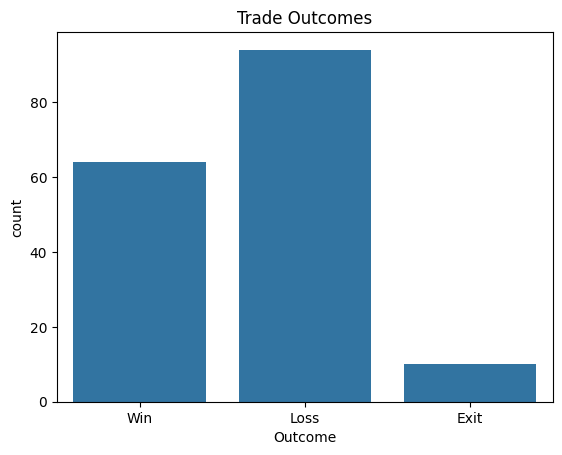

In [6]:
# Outcome distribution
sns.countplot(data=df, x="Outcome")
plt.title("Trade Outcomes")
plt.show()

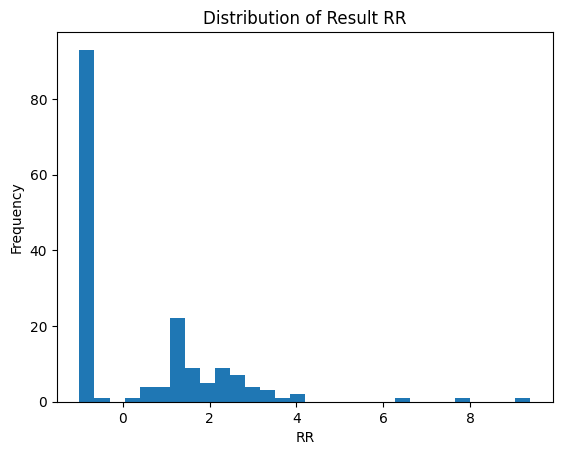

In [7]:
# Result RR Distribution
plt.hist(df["Result RR"], bins=30)
plt.title("Distribution of Result RR")
plt.xlabel("RR")
plt.ylabel("Frequency")
plt.show()

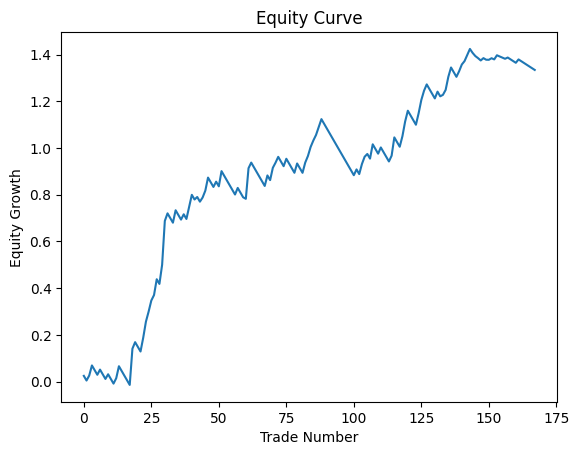

In [8]:
# Equity Growth

df["PnL"] = df["Result RR"] * (df["Risk %"] / 100)
df["Equity"] = df["PnL"].cumsum()

plt.plot(df["Equity"])
plt.title("Equity Curve")
plt.xlabel("Trade Number")
plt.ylabel("Equity Growth")
plt.show()

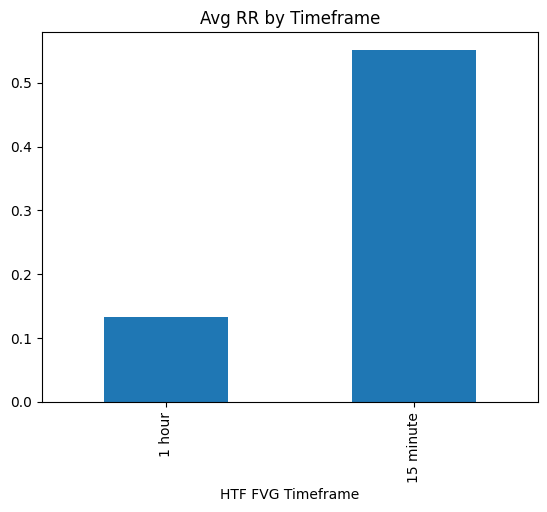

In [9]:
# Avg RR by timeframe

df.groupby("HTF FVG Timeframe")["Result RR"].mean().plot(kind="bar")
plt.title("Avg RR by Timeframe")
plt.show()

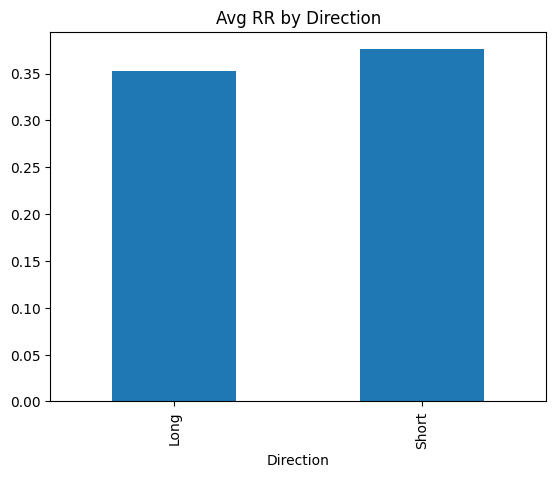

In [10]:
# Avg RR by direction

df.groupby("Direction")["Result RR"].mean().plot(kind="bar")
plt.title("Avg RR by Direction")
plt.show()

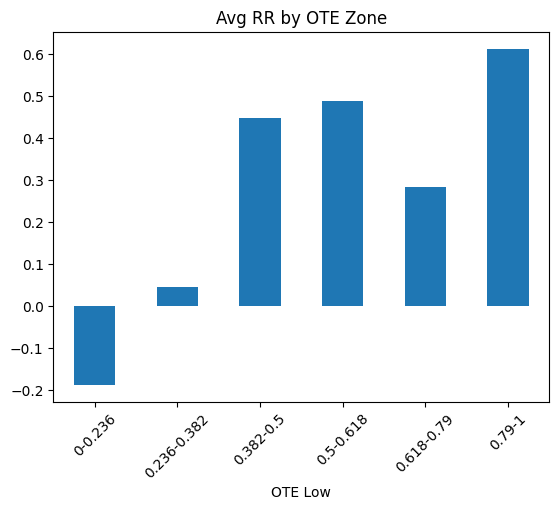

In [11]:
# Avg RR by OTE zones

df.groupby("OTE Low")["Result RR"].mean().plot(kind="bar")
plt.title("Avg RR by OTE Zone")
plt.xticks(rotation=45)
plt.show()

In [12]:
# Expectancy when taking ALL trades

wins = df[(df["Outcome"] == "Win")]["Result RR"]
losses = df[df["Outcome"].isin(["Loss", "Exit"])]["Result RR"]

winrate = len(wins) / len(df)
lossrate = len(losses) / len(df)

avg_win = wins.mean()
avg_loss = abs(losses.mean())

expectancy = (winrate * avg_win) - (lossrate * avg_loss)

print("Expectancy: ", expectancy)
print("Total Trades: ", len(df))

Expectancy:  0.36488095238095225
Total Trades:  168


In [22]:
# Expectancy NOT taking OTE ranges of 0-0.382

df_filtered = df[
    (~df["OTE Low"].isin(["0-0.236", "0.236-0.382"]))
]

wins = df_filtered[df_filtered["Outcome"]== "Win"]["Result RR"]
losses = df_filtered[df_filtered["Outcome"].isin(["Loss", "Exit"]) ]["Result RR"]

winrate = len(wins) / len(df_filtered)
lossrate = len(losses) / len(df_filtered)

avg_win = wins.mean()
avg_loss = abs(losses.mean())

expectancy = (winrate * avg_win) - (lossrate * avg_loss)

print("Expectancy: ", expectancy)
print("Total Trades: ", len(df_filtered))
print("Winrate: ", winrate)
df_filtered["Result RR"].describe()

Expectancy:  0.42472222222222217
Total Trades:  144
Winrate:  0.3888888888888889


count    144.000000
mean       0.424722
std        1.862646
min       -1.000000
25%       -1.000000
50%       -1.000000
75%        1.455000
max        9.390000
Name: Result RR, dtype: float64

In [ ]:
# Expectancy NOT taking OTE ranges of 0-0.382 AND no big wins > 6
# Optimised strategy

df_filtered2 = df_filtered[df_filtered["Result RR"] < 6]

wins = df_filtered2[df_filtered2["Outcome"]== "Win"]["Result RR"]
losses = df_filtered2[df_filtered2["Outcome"].isin(["Loss", "Exit"])]["Result RR"]

winrate = len(wins) / len(df_filtered2)
lossrate = len(losses) / len(df_filtered2)

avg_win = wins.mean()
avg_loss = abs(losses.mean())

expectancy = (winrate * avg_win) - (lossrate * avg_loss)

print("Expectancy (No outliers):", expectancy)
print("Total Trades: ", len(df_filtered2))
print("Winrate: ", winrate)
df_filtered2["Result RR"].describe()

Expectancy (No outliers): 0.26574468085106373
Total Trades:  141
Winrate:  0.44680851063829785


count    141.000000
mean       0.265745
std        1.514249
min       -1.000000
25%       -1.000000
50%       -1.000000
75%        1.410000
max        4.090000
Name: Result RR, dtype: float64

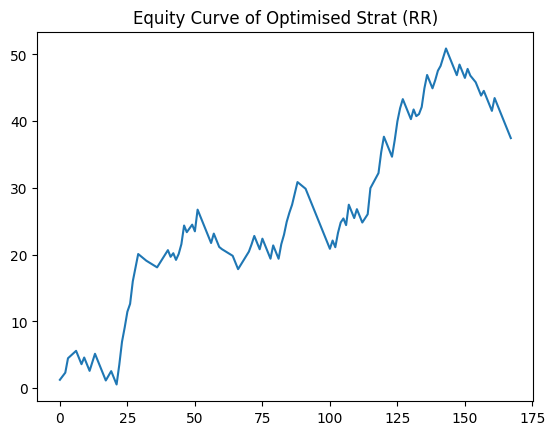

10


Result RR
0     64
1     29
2     22
3     11
4      6
5      3
6      2
7      1
8      1
9      1
10     1
Name: count, dtype: int64

In [15]:
# More data of optimised strategy

plt.plot((df_filtered2["Result RR"]).cumsum())
plt.title("Equity Curve of Optimised Strat (RR)")
plt.show()

loss_streak = (df_filtered2["Result RR"] == -1).astype(int)

streaks = loss_streak.groupby((loss_streak != loss_streak.shift()).cumsum()).cumsum()

print(streaks.max())
streaks.value_counts().sort_index()

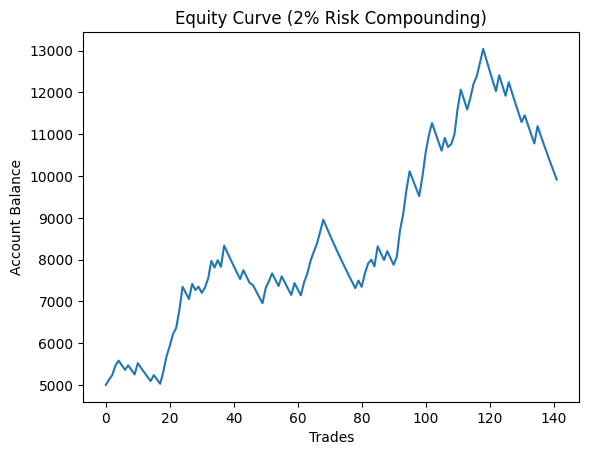

Max drawdown %: -23.976179479717246


In [16]:
# Simulating live trading with 5000 starting capital
# risking 2% per trade using optimised strat.

capital = 5000
risk_pct = 0.02

equity = [capital]

for rr in df_filtered2["Result RR"]:
    risk_amount = capital * risk_pct # 2% of current equity
    pnl = rr * risk_amount # convert RR to money

    capital += pnl
    equity.append(capital)

df_filtered2 = df_filtered2.copy()
df_filtered2["Equity"] = equity[1:]

plt.plot(equity)
plt.title("Equity Curve (2% Risk Compounding)")
plt.xlabel("Trades")
plt.ylabel("Account Balance")
plt.show()

# Show drawdowns

peak = equity[0]
drawdowns = []

for e in equity:
    if e > peak:
        peak = e
    drawdown = (e - peak) / peak
    drawdowns.append(drawdown)

print("Max drawdown %:", min(drawdowns) * 100)

In [17]:
# Monte Carlo simulation of optimised strategy

n_trades = 100
runs = 1000

results = []

for _ in range(runs):
    capital = 5000
    equity = []

    for _ in range(n_trades):
        rr = np.random.choice(df_filtered2["Result RR"])

        risk = capital * 0.02
        capital += rr * risk

        equity.append(capital)

    results.append(capital)

print("Avg final equity: ", np.mean(results))
print("Best case: ", np.max(results))
print("Worst case: ", np.min(results))
np.percentile(results, [5, 25, 50, 75, 95])

Avg final equity:  8475.966195448624
Best case:  25281.158265122845
Worst case:  3076.772451425081


array([ 5051.8974462 ,  6629.21067411,  8032.29500374,  9756.05459088,
       13597.02822378])

In [18]:
# Probability of passing prop firm challenges

rr_list = df_filtered2["Result RR"].values

def run_challenge(rr_list, start_cap=10000, 
                  risk_pct=0.005,
                  profit_target=1.10, max_dd=0.9,
                  n_trades=50): #Change n_trades where needed
    
    capital = start_cap
    peak = start_cap

    for _ in range(n_trades):

        rr = np.random.choice(rr_list)

        risk = capital * risk_pct
        capital += rr * risk

        peak = max(peak, capital)
        drawdown = capital / peak

        # hit max drawdown rule
        if drawdown <= max_dd:
            return "Fail"
        
        # hit profit target
        if capital >= start_cap * profit_target:
            return "Pass"
        
    return "Fail"

runs = 5000

results = []

for _ in range(runs):
    results.append(run_challenge(rr_list, risk_pct=0.01))

pass_rate = results.count("Pass") / runs

print("Pass Probability: ", pass_rate)

Pass Probability:  0.714


In [19]:
# How many trades (avg) to reach prop firm goals

rr_list = df_filtered2["Result RR"].values

def time_to_target(rr_list, start_cap=1.0, 
                   risk_pct=0.005,
                   target=1.10, max_trades=200):
    
    capital = start_cap
    for i in range(max_trades):

        rr = np.random.choice(rr_list)

        capital += capital * risk_pct * rr
        
        if capital >= target:
            return i + 1 # trades taken
        
        if capital <= 0.9:
            return max_trades #failed path
        
    return max_trades

runs = 5000

results = []

for _ in range(runs):
    results.append(time_to_target(rr_list, risk_pct=0.005))

results = np.array(results)

print("Median trades to 10%: ", np.median(results))
print("Mean trades to 10%: ", np.mean(results))
print("Best Case: ", np.min(results))
print("worst case: ", np.max(results))

Median trades to 10%:  64.0
Mean trades to 10%:  75.3642
Best Case:  8
worst case:  200


In [20]:
# See the effects of news on strategy performance

# Use the filtered dataset
df_filtered2 = df_filtered[df_filtered["Result RR"] < 6]

# Splitting the dataset
news_yes = df_filtered2[df_filtered2["News"] == "Yes"]
news_no = df_filtered2[df_filtered2["News"] == "No"]

def calc_stats(data):
    wins = data[data["Outcome"] == "Win"]["Result RR"]
    losses = data[data["Outcome"].isin(["Loss", "Exit"])]["Result RR"]

    winrate = len(wins) / len(data)
    avg_win = wins.mean()
    avg_loss = abs(losses.mean())

    expectancy = (winrate * avg_win) - ((1 - winrate) * avg_loss)

    return winrate, expectancy, len(data)

# Stats
wr_yes, exp_yes, n_yes = calc_stats(news_yes)
wr_no, exp_no, n_no = calc_stats(news_no)
wr_all, exp_all, n_all = calc_stats(df_filtered2)

print("=== NEWS = YES ===")
print("Trades: ", n_yes)
print("Winrate: ", wr_yes)
print("Expectancy: ", exp_yes)

print("\n=== NEWS = No ===")
print("Trades: ", n_no)
print("Winrate: ", wr_no)
print("Expectancy: ", exp_no)

print("\n=== ALL TRADES ===")
print("Trades: ", n_all)
print("Winrate: ", wr_all)
print("Expectancy: ", exp_all)

=== NEWS = YES ===
Trades:  30
Winrate:  0.4666666666666667
Expectancy:  0.40966666666666657

=== NEWS = No ===
Trades:  111
Winrate:  0.35135135135135137
Expectancy:  0.22684684684684697

=== ALL TRADES ===
Trades:  141
Winrate:  0.375886524822695
Expectancy:  0.26574468085106373
